# TP Integrador: Venta y Recomendación de Eventos 
**Bases de Datos Integradas:** MongoDB + Redis + Neo4j

**Integrantes:** 
* Agustín Ghizzo
* Joaquín Meza

---


## Celda de importaciones y conexiones

In [1]:
import os 
import redis 
import matplotlib.pyplot as plt
from pymongo import MongoClient 
from neo4j import GraphDatabase
from pprint import pprint

# Conexiones
MONGO_HOST = "mongo"
REDIS_HOST = "redis"
NEO4J_HOST = "neo4j"

MONGO_USER = os.getenv("MONGO_INITDB_ROOT_USERNAME", "admin")
MONGO_PASS = os.getenv("MONGO_INITDB_ROOT_PASSWORD", "admin123")
REDIS_PASS = os.getenv("REDIS_PASSWORD", "redis123")
NEO4J_PASS = os.getenv("NEO4J_PASSWORD", "neo4j123")

MONGO_URI = f"mongodb://{MONGO_USER}:{MONGO_PASS}@{MONGO_HOST}:27017/?authSource=admin"
NEO4J_URI = f"bolt://{NEO4J_HOST}:7687"

# Inicialización de conexiones 

try:
    mongo_client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    db_mongo = mongo_client["tpIntegrador"]
    mongo_client.admin.command('ping')
    print("Conexión a MongoDB exitosa")

    redis_client = redis.Redis(host=REDIS_HOST, port=6379, password=REDIS_PASS, decode_responses=True)
    redis_client.ping()
    print("Conexión exitosa a Redis")

    neo4j_driver = GraphDatabase.driver(NEO4J_URI, auth=("neo4j", NEO4J_PASS))
    with neo4j_driver.session() as session:
        session.run("RETURN 1")
    print("Conexión a Neo4j exitosa")

except Exception as e:
    print(f"Error de conexion: {e}")


# Se instancia fecha referencia en formato ISO

FECHA_REFERENCIA = "2026-10-01"

Conexión a MongoDB exitosa
Conexión exitosa a Redis
Conexión a Neo4j exitosa


In [2]:
#celda provisoria de importaciones
import sys
import os

sys.path.append(os.path.abspath("../python"))
sys.path.append("/work")

print("1\. Directorio de trabajo actual:", os.getcwd()) 
print("2\. Archivos/Carpetas aquí:", os.listdir('.')) 
if os.path.exists('/work'): 
    print("3\. Contenido de /work:", os.listdir('/work'))

1\. Directorio de trabajo actual: /work
2\. Archivos/Carpetas aquí: ['.ipynb_checkpoints', '.Trash-1000', 'python', 'src', 'tpIntegrador.ipynb']
3\. Contenido de /work: ['.ipynb_checkpoints', '.Trash-1000', 'python', 'src', 'tpIntegrador.ipynb']


## EJERCICIO 1 - Importaciones y limpieza las bases de datos 
---

In [3]:
# provisorio:

from src.carga_inicial import insert_mongo, insert_neo4j, insert_redis
#Carga de bases de datos
    #Las bases de datos se limpian en el codigo de carga
insert_mongo(db_mongo)
insert_redis(redis_client)
#Al insertar las relaciones en neo, tambien debemos pasarle la base de mongo para que elimine los datos duplicados en la misma
insert_neo4j(neo4j_driver,db_mongo)

Cargando datos en MongoDB
 • Usuarios: 6 insertados
 • Artistas: 6 insertados
 • Lugares: 4 insertados
 • Eventos: 8 insertados
 • Compras: 12 insertados
MongoDB cargado correctamente
Redis cargado con éxito.
Neo4J se cargo correctamente


True


## EJERCICIO 2 - Flujo de compra
* Reservar entradas para un usuario y un evento. Solo se permite si el usuario tiene una sesión
activa y hay disponibilidad suficiente.
* Confirmar una reserva vigente. Se genera la compra con el precio actual del evento. Si la reserva
venció, debe informarse el error.
* Cancelar una reserva, liberando las entradas.
> **Demostrar al menos tres casos:** una compra exitosa, un intento sin disponibilidad suficiente y una
cancelación.

---

### Reservar entradas para un usuario y un evento

In [4]:
from src.consultas_extras import (reservas_vigentes, entradas_vendidas)
#Caso intento sin disponibilidad suficiente
ID_USER = 1
ID_EVENTO = 5
CANTIDAD_INSUFICIENTE = 600
CANTIDAD_SUFICIENTE = 10
def entradas_disponibles(redis_client,db,id_evento,cantidad,cupo):
    entradas_disponibles = cupo - reservas_vigentes(redis_client,id_evento) - entradas_vendidas(db,id_evento)
    if (entradas_disponibles < cantidad):
        print("No hay entradas disponibles para la cantidad pedida")
        return False
    else: return True

def reservar_entrada(id_usuario,id_evento,cant,redis_client,db):
    #Crea la clave de redis
    evento = db.eventos.find_one({"evento_id" : id_evento})
    if not evento:
            print("No se encontro el evento")
            return False
    
    sesion = f"sesion:usuario:{id_usuario}"
    if redis_client.exists(sesion):
        cupo = evento.get("cupo", 0)
        nombre_evento = evento.get("nombre")
        if entradas_disponibles(redis_client,db,id_evento,cant,cupo):
            clave = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
            valor = f"{cant}"
            redis_client.set(clave,valor, ex = 600)
            print(f"Se reservaron {cant} entradas para el evento {nombre_evento}")
        else:
            return False
    else:
            print("El usuario no posee una sesion activa")

#Vuelvo a cargar las sesiones activas
insert_redis(redis_client)
reservar_entrada(ID_USER,ID_EVENTO,CANTIDAD_INSUFICIENTE,redis_client,db_mongo)

#Caso reserva exitosa
reservar_entrada(ID_USER,ID_EVENTO,CANTIDAD_SUFICIENTE,redis_client,db_mongo)

Redis cargado con éxito.
No hay entradas disponibles para la cantidad pedida
Se reservaron 10 entradas para el evento Viento Norte en sala


### Confirmar una reserva vigente.

In [5]:
ID_USER = 1
ID_EVENTO = 5

def confirmar_reserva(db,redis_client,id_usuario,id_evento):
    reserva_vigente = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
    
    if redis_client.exists(reserva_vigente):
        cantidad = int(redis_client.get(reserva_vigente))
        
        ultima_compra = db.compras.find_one(sort=[("compra_id", -1)])
        nueva_id = (ultima_compra["compra_id"] + 1) if ultima_compra else 1

        precio_evento = db.eventos.find_one({"evento_id" : id_evento})
        
        compra_gen = {
                            "compra_id" : nueva_id,
                            "usuario_id" : id_usuario,
                            "evento_id" : id_evento,
                            "cantidad" : cantidad,
                            "precio_unitario" : precio_evento["precio"],
                            "total" : cantidad * precio_evento["precio"],
                            "fecha_compra" : FECHA_REFERENCIA,
                            "estado" : "confirmada"
                        }
        db.compras.insert_one(compra_gen)
        print("La compra se realizo correctamente")
        redis_client.delete(reserva_vigente)
    else: 
        print("ERROR: La reserva esta cancelada o expiro su tiempo")

confirmar_reserva(db_mongo,redis_client,ID_USER,ID_EVENTO)

La compra se realizo correctamente


### Cancelar una reserva.

In [6]:
ID_USER = 1
ID_EVENTO = 5

def cancelar_reserva(db,redis_client,id_usuario,id_evento):
    reserva_cancelada = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
    if redis_client.exists(reserva_cancelada):
        redis_client.delete(reserva_cancelada)
        print("La reserva se cancelo correctamente")
    else: print("No existe una reserva para este evento")

cancelar_reserva(db_mongo,redis_client,ID_USER,ID_EVENTO)

No existe una reserva para este evento


## EJERCICIO 3 - 12 CONSULTAS 

1. Usuarios que asistieron a algún evento de "Los Cóndores Eléctricos".
2. Amigos de Juan López que siguen algún artista que también sigue Juan. Mostrar el nombre del amigo y el artista.
3. Recomendar a Juan artistas que siguen sus amigos y que él no sigue, ordenados por cantidad de amigos que los siguen.
4. Para los artistas del punto anterior, listar sus eventos futuros con lugar, ciudad, fecha, precio y entradas disponibles.
5. Artistas similares a los que sigue Lucía Romero y que ella no sigue.
6. Eventos futuros en La Plata con precio menor a $40.000.
7. Cantidad de eventos futuros por género.
8. Total gastado por cada usuario en compras confirmadas, ordenado de mayor a menor.
9. Entradas vendidas por evento, incluyendo los eventos sin ventas.
10. Usuarios conectados en este momento.
11. Reservas vigentes: usuario, evento, cantidad y tiempo restante antes de que venzan.
12. Los 3 géneros más buscados.
---

### 1) Usuarios que asistieron a algún evento de "Los Cóndores Eléctricos"

In [7]:
artista = db_mongo.artistas.find_one({"nombre":"Los Cóndores Eléctricos"})
artista_id = artista["artista_id"] 

eventos_pasados = db_mongo.eventos.find({"artistas":artista_id, "fecha":{"$lt":FECHA_REFERENCIA} })
eventos_ids = [e["evento_id"] for e in eventos_pasados]

compras_confirmadas = db_mongo.compras.find({"evento_id": {"$in": eventos_ids }, "estado": "confirmada"})

#Quitando duplicados
usuarios_ids = list(set(c["usuario_id"] for c in compras_confirmadas))

usuarios = db_mongo.usuarios.find({"usuario_id": {"$in": usuarios_ids}})

#Imprimiendo

print("Usuarios que asistieron a al menos un evento de 'Los cóndores Eléctricos': ")
for usu in usuarios:
    print(f" {usu['nombre']} (ID: {usu['usuario_id']})")


Usuarios que asistieron a al menos un evento de 'Los cóndores Eléctricos': 
 Juan López (ID: 2)
 Valentina Ruiz (ID: 5)


### 2) Amigos de Juan López que siguen algún artista que también sigue Juan. Mostrar el nombre del amigo y el artista.

In [8]:
query_2 = """
MATCH (juan:Usuario {nombre: "Juan López"})-[:AMIGO_DE]-(amigo:Usuario), (juan)-[:SIGUE]->(artista:Artista), (amigo)-[:SIGUE]->(artista)
RETURN amigo.nombre, artista.nombre
"""

with neo4j_driver.session() as session:
    for r in session.run(query_2):
        print(f"Con el amigo: {r['amigo.nombre']} comparten al artista: {r['artista.nombre']}")

Con el amigo: Martín Díaz comparten al artista: Pulso Nocturno
Con el amigo: Martín Díaz comparten al artista: Pulso Nocturno
Con el amigo: Valentina Ruiz comparten al artista: Los Cóndores Eléctricos
Con el amigo: Valentina Ruiz comparten al artista: Los Cóndores Eléctricos


### 3) Recomendar a Juan artistas que siguen sus amigos y que él no sigue, ordenados por cantidad de amigos que los siguen.

In [9]:
query_3= """
MATCH (juan:Usuario {nombre: "Juan López"})-[:AMIGO_DE]-(amigo:Usuario)-[:SIGUE]->(artista:Artista)
WITH juan, artista, amigo, EXISTS((juan)-[:SIGUE]->(artista)) AS juan_ya_lo_sigue
WHERE NOT juan_ya_lo_sigue
RETURN artista.nombre, COUNT(amigo) AS cantidad_amigos
ORDER BY cantidad_amigos DESC
"""

with neo4j_driver.session() as session:
    for r in session.run(query_3):
        print(f"Artista recomendado: {r['artista.nombre']} , seguido por {r['cantidad_amigos']} de tus amigos")


Artista recomendado: Radio Neón , seguido por 4 de tus amigos
Artista recomendado: Cumbia Satelital , seguido por 2 de tus amigos
Artista recomendado: Viento Norte , seguido por 2 de tus amigos
Artista recomendado: La Marea Sur , seguido por 2 de tus amigos


### 4) Para los artistas del punto anterior, listar sus eventos futuros con lugar, ciudad, fecha, precio y entradas disponibles.

In [10]:
with neo4j_driver.session() as session:
    nombres_recomendados = [r['artista.nombre'] for r in session.run(query_3)]

artistas_mongo = db_mongo.artistas.find({"nombre": {"$in": nombres_recomendados}})
ids_recomendados = [artista['artista_id'] for artista in artistas_mongo]

eventos_futuros_recomendados = db_mongo.eventos.find({
    'artistas':{'$in':ids_recomendados},
    'fecha':{'$gt':FECHA_REFERENCIA},
    'estado':'activo'
})
for e in eventos_futuros_recomendados:
    lugar = db_mongo.lugares.find_one({
        'lugar_id':e['lugar_id']
    })
    print(f"Evento recomendado: {e['nombre']} el {e['fecha']} a ${e['precio']} en {lugar['ciudad']}")



Evento recomendado: Rock del Lago el 2026-11-14 a $38000 en Córdoba
Evento recomendado: Viento Norte en sala el 2026-10-24 a $20000 en La Plata
Evento recomendado: Fiesta Satelital el 2026-12-05 a $30000 en La Plata
Evento recomendado: Radio Neón Tour el 2026-10-10 a $22000 en Rosario


### 5) Artistas similares a los que sigue Lucía Romero y que ella no sigue.

In [11]:
query_5 = """
MATCH (lucia:Usuario {nombre: "Lucía Romero"})-[:SIGUE]->(a:Artista)-[:SIMILAR_A]-(s:Artista)
WHERE NOT (lucia)-[:SIGUE]->(s)
RETURN s.nombre AS similar, collect(DISTINCT a.nombre) AS porque_sigue_a
"""
with neo4j_driver.session() as session:
    for r in session.run(query_5):
        print(f"{r['similar']} (similar a {', '.join(r['porque_sigue_a'])})")

Pulso Nocturno (similar a Cumbia Satelital)
Viento Norte (similar a La Marea Sur)


### 6) Eventos futuros en La Plata con precio menor a $40.000.

In [12]:
lugares_lp = [l["lugar_id"] for l in db_mongo.lugares.find({"ciudad": "La Plata"})]
eventos_futuros_baratos = db_mongo.eventos.find({
    'lugar_id':{'$in': lugares_lp},
    'precio':{'$lt':40000},
    'estado':'activo',
    'fecha': {'$gt': FECHA_REFERENCIA}
})

for evento in eventos_futuros_baratos:
    lugar = db_mongo.lugares.find_one({'lugar_id':evento['lugar_id']})
    print(f"Te recomendamos asistir a {evento['nombre']} por solo ${evento['precio']} el día: {evento['fecha']} en {lugar['nombre']}")


Te recomendamos asistir a Fiesta Satelital por solo $30000 el día: 2026-12-05 en Estadio Ciudad
Te recomendamos asistir a Viento Norte en sala por solo $20000 el día: 2026-10-24 en Sala Diagonal


### 7) Cantidad de eventos futuros por género.

In [13]:
#Uso una agreggation pipeline

pipeline_7 = [
    {'$match': {'fecha': {'$gte':FECHA_REFERENCIA}}},
    {'$group': {'_id': '$genero', 'cantidad_eventos':{'$sum':1}}}
]

ev_futuros_por_genero = db_mongo.eventos.aggregate(pipeline_7)


for resultado in ev_futuros_por_genero:
    print(f"{resultado['_id']}: {resultado['cantidad_eventos']} eventos")


cumbia: 1 eventos
folk: 1 eventos
electrónica: 1 eventos
rock: 2 eventos


### 8) Total gastado por cada usuario en compras confirmadas, ordenado de mayor a menor.

In [14]:
pipeline_8 = [
    {'$match':{'estado':'confirmada'}},
    {'$group':{'_id': '$usuario_id','total':{'$sum':'$total'}}},
    {'$sort':{'total': -1}}
]

for r in db_mongo.compras.aggregate(pipeline_8):
    u = db_mongo.usuarios.find_one({'usuario_id': r['_id']})
    print(f"{u['nombre']}: ${r['total']:,}")

Sofía Martínez: $312,000
Valentina Ruiz: $165,000
Juan López: $115,000
Martín Díaz: $115,000
Tomás Herrera: $22,000
Lucía Romero: $18,000


###  9) Entradas vendidas por evento, incluyendo los eventos sin ventas.

In [15]:
#Traigo todos los eventos
todos_los_eventos = db_mongo.eventos.find({})

for evento in todos_los_eventos:
    compras_del_evento = db_mongo.compras.find({
        "evento_id": evento["evento_id"],
        "estado": "confirmada"
    })

    total_entradas = sum([compra["cantidad"] for compra in compras_del_evento])
    
    print(f"Evento: {evento['nombre']} - Entradas vendidas: {total_entradas}")

Evento: Cóndores en vivo - Entradas vendidas: 3
Evento: Marea acústica - Entradas vendidas: 3
Evento: Noche Pulso - Entradas vendidas: 4
Evento: Rock del Lago - Entradas vendidas: 2
Evento: Viento Norte en sala - Entradas vendidas: 12
Evento: Fiesta Satelital - Entradas vendidas: 4
Evento: Radio Neón Tour - Entradas vendidas: 1
Evento: Pulso Estadio - Entradas vendidas: 0


### 10. Usuarios conectados en este momento.

In [16]:
#provisorio
claves_activas = redis_client.keys('sesion:usuario*') 

if not claves_activas:
    print("No hay ningún usuario conectado en este momento.")

for clave in claves_activas:
    valor = redis_client.get(clave)
    
    print(f"Registro activo en Redis -> Clave: {clave}, Fecha: {valor}")

Registro activo en Redis -> Clave: sesion:usuario:1, Fecha: 2026-10-01/15:18:40.572818
Registro activo en Redis -> Clave: sesion:usuario:6, Fecha: 2026-10-01/15:18:40.572818
Registro activo en Redis -> Clave: sesion:usuario:2, Fecha: 2026-10-01/15:18:40.572818


### 11. Reservas vigentes: usuario, evento, cantidad y tiempo restante antes de que venzan.

In [17]:
claves_reservas = redis_client.keys('reserva:evento:*')


if not claves_reservas:
    print("No hay reservas vigentes en este momento.")

#redis_client.setex("reserva:usuario_2:evento_1", 300, "cantidad: 2")

for clave in claves_reservas:
    # 2. Le preguntamos a Redis los segundos exactos que le quedan de vida a esa llave
    tiempo_restante = redis_client.ttl(clave)
    
    # 3. Traemos los datos guardados (usuario, evento, cantidad)
    datos_reserva = redis_client.get(clave)
    
    print(f"Reserva: {clave} | Datos: {datos_reserva} | Vence en: {tiempo_restante} segundos")

Reserva: reserva:evento:4:usuario:6 | Datos: 3 | Vence en: 598 segundos
Reserva: reserva:evento:5:usuario:3 | Datos: 2 | Vence en: 598 segundos


### 12. Los 3 géneros más buscados.

In [18]:
top3 = redis_client.zrevrange("busqueda:reciente", 0, 2, withscores=True)
for genero, puntaje in top3:
    print(f"{genero}: {int(puntaje)} búsquedas")

rock: 7 búsquedas
electrónica: 5 búsquedas
folk: 3 búsquedas


## Ejercicio 4 - Estadísticas y gráficos

Generar las siguientes estadísticas, mostrando el valor para cada elemento (no solo el máximo):
* Cantidad de seguidores por artista.
* Recaudación por evento (compras confirmadas).
* Entradas vendidas por lugar.
* Cantidad de búsquedas por género.

Representar al menos dos de estas estadísticas con gráficos hechos con matplotlib. Los datos de los gráficos deben obtenerse consultando las bases, no desde las listas de Python del dataset.

---

In [19]:
# Función reutilizada de un proyecto anterior, adaptada para jupyterlab:

def generar_grafico_generico(datos_x, datos_y, tipo_grafico="bar", titulo="", x_etiqueta="", y_etiqueta="", **kwargs):
    """
    Crea un gráfico de Matplotlib según los argumentos recibidos y lo renderiza en Streamlit
    """
    fig, ax = plt.subplots(figsize=kwargs.get('figsize', (10, 6)))
    if tipo_grafico == 'bar':
        ax.bar(datos_x, datos_y, color=kwargs.get('color', '#4db6ac'))
        plt.xticks(rotation=45)
    elif tipo_grafico == 'line':
        ax.plot(datos_x, datos_y, marker='o', color=kwargs.get('color', '#e74c3c'))
        plt.xticks(rotation=45)
    elif tipo_grafico == 'pie':
        ax.pie(datos_y, labels=datos_x, autopct='%1.1f%%', shadow=True)
    elif tipo_grafico == 'barh':
        ax.barh(datos_x, datos_y, color=kwargs.get('color', '#4db6ac'))
        labelsize = kwargs.get('labelsize', None)
        if labelsize:
            ax.tick_params(axis='y', labelsize=labelsize)

    ax.set_title(titulo)
    if tipo_grafico != "pie":
        ax.set_xlabel(x_etiqueta)
        ax.set_ylabel(y_etiqueta)

    fig.tight_layout()
    plt.show(fig)

### Mostrando cantidad de seguidores por artista

  Pulso Nocturno: 3 seguidores
  Radio Neón: 3 seguidores
  Cumbia Satelital: 2 seguidores
  La Marea Sur: 2 seguidores
  Los Cóndores Eléctricos: 2 seguidores
  Viento Norte: 1 seguidores


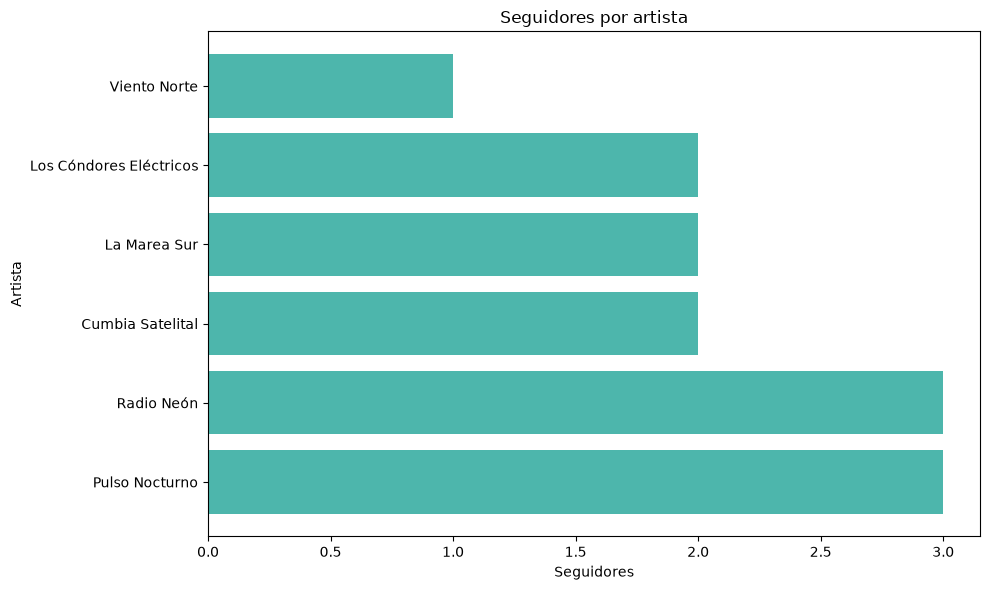

In [20]:
query_seguidores = """
MATCH (a:Artista)
OPTIONAL MATCH (u:Usuario)-[:SIGUE]->(a)
RETURN a.nombre AS artista, count(u) AS seguidores
ORDER BY seguidores DESC, artista
"""

with neo4j_driver.session() as session:
    res = session.run(query_seguidores).data()

for r in res:
    print(f"  {r['artista']}: {r['seguidores']} seguidores")

artistas_x = [r["artista"] for r in res]
seguidores_y = [r["seguidores"] for r in res]

generar_grafico_generico(artistas_x, seguidores_y, "barh","Seguidores por artista", "Seguidores", "Artista")

### Cantidad de búsquedas por género.

rock: 7 búsquedas
electrónica: 5 búsquedas
folk: 3 búsquedas
cumbia: 2 búsquedas


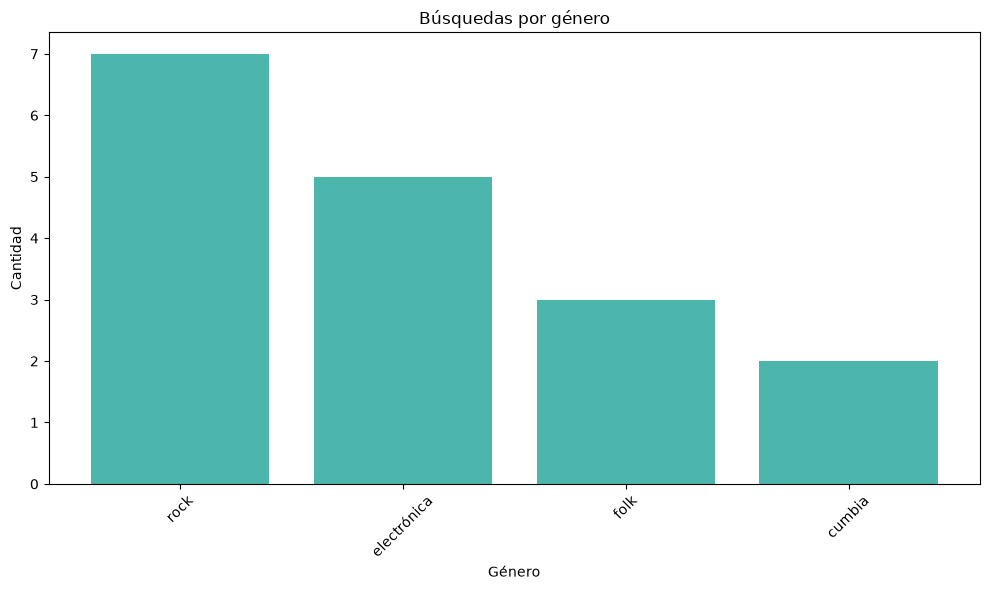

In [21]:
#Provisorio
busq = redis_client.zrevrange("busqueda:reciente", 0, -1, withscores=True)
if busq:
    generos = [g for g, _ in busq]
    cantidades = [int(c) for _, c in busq]
    
    for g, c in zip(generos, cantidades):
        print(f"{g}: {c} búsquedas")
    
    generar_grafico_generico(generos, cantidades, "bar","Búsquedas por género", "Género", "Cantidad")
else: print("No hay busquedas recientes para generar el grafico")

### Entradas vendidas por lugar.

Recaudación por evento (compras confirmadas):
  Viento Norte en sala: $240,000
  Cóndores en vivo: $135,000
  Fiesta Satelital: $120,000
  Noche Pulso: $100,000
  Rock del Lago: $76,000
  Marea acústica: $54,000
  Radio Neón Tour: $22,000
  Pulso Estadio: $0


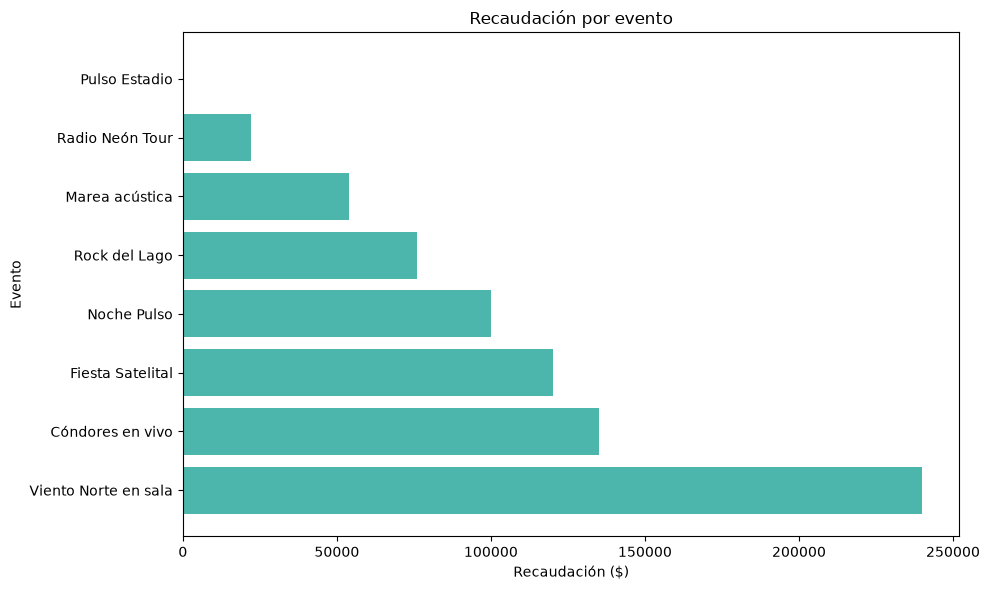

In [22]:
pipeline_recaudacion = [
    {"$lookup": {"from": "compras", "localField": "evento_id","foreignField": "evento_id","pipeline": [{"$match": {"estado": "confirmada"}}],"as": "cs"}},
    {"$project": {"_id": 0, "evento": "$nombre","recaudacion": {"$sum": "$cs.total"}}},
    {"$sort": {"recaudacion": -1, "evento": 1}
    }]

resultados = list(db_mongo.eventos.aggregate(pipeline_recaudacion))
nombres_eventos = [r["evento"] for r in resultados]
recaudacion = [r["recaudacion"] for r in resultados]

print("Recaudación por evento (compras confirmadas):")
for r in resultados:
    print(f"  {r['evento']}: ${r['recaudacion']:,}")

generar_grafico_generico(nombres_eventos, recaudacion, "barh","Recaudación por evento", "Recaudación ($)", "Evento")

  Estadio Ciudad (La Plata): 7 entradas
  Sala Diagonal (La Plata): 15 entradas
  Anfiteatro del Lago (Córdoba): 2 entradas
  Club Río (Rosario): 5 entradas


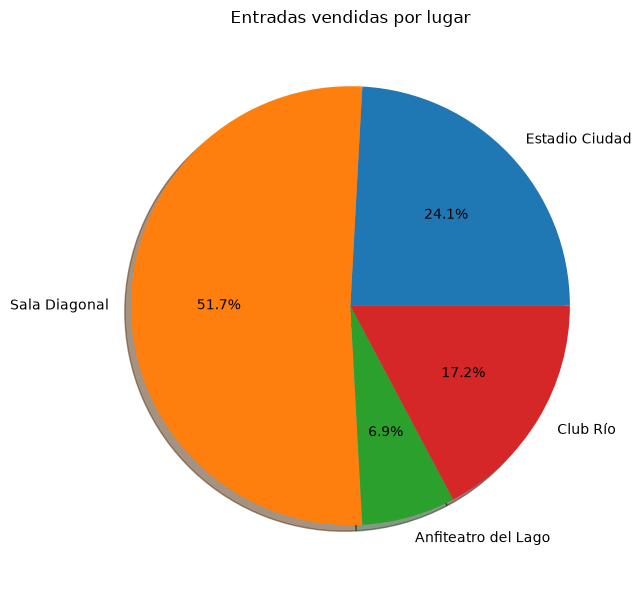

In [23]:
pipeline_lugares = [
    {"$match": {"estado": "confirmada"}},
    {"$lookup": {"from": "eventos","localField": "evento_id","foreignField": "evento_id","as": "ev"}},
    {"$unwind": "$ev"},         
    {"$group": {"_id": "$ev.lugar_id", "cantidad": {"$sum": "$cantidad"}}}
]

vendidas_lugar = {r["_id"]: r["cantidad"] for r in db_mongo.compras.aggregate(pipeline_lugares)}

nombres_lugares = []
entradas = []
for l in db_mongo.lugares.find().sort("lugar_id", 1):  
    cant = vendidas_lugar.get(l["lugar_id"], 0)
    nombres_lugares.append(l["nombre"])
    entradas.append(cant)
    print(f"  {l['nombre']} ({l['ciudad']}): {cant} entradas")

generar_grafico_generico(nombres_lugares, entradas, "pie", "Entradas vendidas por lugar")

## Ejercicio 5 - Modificaciones
1. Aumentar un 10% el precio de los eventos futuros en Rosario.
2. Agregar el servicio "accesibilidad" al lugar con id 2.
3. Cancelar el evento 7.
    * El evento queda cancelado.
    * Sus compras pasan a estado reembolsada.
    * No debe quedar disponibilidad ni reservas de ese evento.
    * No debe aparecer en recomendaciones.
4. Eliminar al usuario Tomás Herrera (id 6) del sistema. Decidir y justificar qué pasa con sus
compras.
5. Eliminar todas las amistades de un usuario a elección.
   
> En los puntos 3 a 5, los cambios deben reflejarse en todas las bases donde haya datos afectados.
Después de cada modificación, mostrar una consulta que evidencie el cambio.

---

### 1. Aumentar un 10% el precio de los eventos futuros en Rosario.

In [24]:
CIUDAD = "Rosario"
def aumentar_precio(db,ciudad):
    #Busca dinamicamente los ids en rosario
    lugares = db.lugares.find({"ciudad": ciudad})
    id = [lugar["lugar_id"] for lugar in lugares]
    filtro = {"lugar_id" : {"$in" : id}, 
            "fecha": {"$gte": FECHA_REFERENCIA}}
    db.eventos.update_many(filtro ,
                           {"$mul": {"precio":1.10}  }
                           )
    
    #Consulta para mostrar los cambios
    eventos = db.eventos.find(filtro)
    for evento in eventos:
        precio = round(evento["precio"], 2)
        print(f"• {evento['nombre']} -> Nuevo precio: {precio}")
aumentar_precio(db_mongo, CIUDAD)

• Radio Neón Tour -> Nuevo precio: 24200.0


### 2. Agregar el servicio "accesibilidad" al lugar con id 2.

In [25]:
ID_LUGAR = 2
def agregar_servicio(db,id):
    #Agrega con addToSet para no duplicar en la lista
    db.lugares.update_one({"lugar_id" : id},
                            {"$addToSet": {"servicios": "accesibilidad"}}
                            )
agregar_servicio(db_mongo,ID_LUGAR)
#Consulta para mostrar el cambio
lugar = db_mongo.lugares.find_one({"lugar_id" : 2})
pprint("Informacion del lugar {ID_LUGAR}")
print(f" Nombre : {lugar['nombre']}")
print(f" Ciudad : {lugar['ciudad']}")
print(f" Capacidad : {lugar['capacidad']}")
print()

'Informacion del lugar {ID_LUGAR}'
 Nombre : Sala Diagonal
 Ciudad : La Plata
 Capacidad : 800



### 3. Cancelar el evento 7.

In [26]:
ID_EVENTO = 7
def cancelar_evento(db,redis_cliente, id):
    db.eventos.update_one({"evento_id" : id},
                          {"$set" : {"estado" : "cancelado"}})

    db.compras.update_many({"evento_id" : id, "estado" : "confirmada"},
                           {"$set" : {"estado" : "reembolsada"}})

    reserva = f"reserva:evento:{id}:*"
    claves_reserva = redis_cliente.keys(reserva)
    if claves_reserva:
        redis_cliente.delete(*claves_reserva)

cancelar_evento(db_mongo,redis_client,ID_EVENTO)

# Comprobar evento en MongoDB
evento = db_mongo.eventos.find_one({"evento_id": ID_EVENTO})
print(f"ESTADO DEL EVENTO {evento['evento_id']}")
print(f" Nombre : {evento['nombre']}")
print(f" Género : {evento['genero']}")
print(f" Estado : {evento['estado']}")
print()
# Comprobar compras asociadas
compras = db_mongo.compras.find({"evento_id": ID_EVENTO})
for c in compras:
    print(f"Compra {c['compra_id']} | Usuario {c['usuario_id']} | Total: {c['total']:,} | Estado: {c['estado']}")

print()
reserva = f"reserva:evento:{ID_EVENTO}:*"
claves_reserva = redis_client.keys(reserva)
if (not claves_reserva):
    print("Se eliminaron las reservas correctamente")
else: print("La reserva no se elimino")

ESTADO DEL EVENTO 7
 Nombre : Radio Neón Tour
 Género : rock
 Estado : cancelado

Compra 10 | Usuario 6 | Total: 22,000 | Estado: reembolsada

Se eliminaron las reservas correctamente


### 4. Eliminar al usuario Tomás Herrera.
> Se decide dejar las compras en la base de datos pero se cambia su estado a anulado. Esto es porque creemos que es informacion necesaria para el negocio y que pueden servir para descubrir ciertos patrones con la baja de usuarios

In [27]:
ID_USER = 6

def eliminar_usuario(db,redis_cliente,usuario_id,driver):
    db.usuarios.delete_one({"usuario_id" : usuario_id})
    #Las compras deben quedar en el sistema porque son informacion necesaria para el negocio
    db.compras.update_many({"usuario_id" : usuario_id},
                           {"$set" : {"estado" : "anulado"}})
    
    #Elimino al usuario de las otras bases
        #Redis
    sesiones_eliminada = f"sesion:usuario:{usuario_id}"
    reserva_eliminada = f"reserva:evento:*:usuario:{usuario_id}"
    claves_sesion = redis_cliente.keys(sesiones_eliminada)
    claves_reserva = redis_cliente.keys(reserva_eliminada)
    
    if(claves_sesion):
        redis_cliente.delete(*claves_sesion)
        print("Se elimino la sesion correctamente")
    else: print("El usuario no tiene una sesion activa")
    if(claves_reserva):
        redis_cliente.delete(*claves_reserva)
        print("Se elimino la reserva correctamente")
    else: print("El usuario no tiene una reserva activa")
        
        #NEO4J
    usuario_neo4j = """MATCH (u:Usuario {usuario_id: $usuario_id}) DETACH DELETE u"""

    with driver.session() as session:
        resultado = session.run(usuario_neo4j, usuario_id = usuario_id)

eliminar_usuario(db_mongo,redis_client,ID_USER,neo4j_driver) 

#Consultas para verificar que se elimino al usuario.
usuario = db_mongo.usuarios.find_one({"usuario_id" : ID_USER})
compras_usuario = db_mongo.compras.find({"usuario_id" : ID_USER})
pprint(f"Usuario --> {usuario}")

for c in compras_usuario:
    print(f"Compra {c['compra_id']} | Usuario {c['usuario_id']} | Total: {c['total']:,} | Estado: {c['estado']}")

    
#Consulta para verificar relaciones 
consulta = """
            MATCH (u:Usuario {usuario_id:$id})
            OPTIONAL MATCH (u)-[r:AMIGO_DE]-(amigo:Usuario)
            RETURN
                count(r) AS total_relaciones
            """
with neo4j_driver.session() as session:
    resultado = session.run(consulta, id=ID_USER).single()
    print(f"Total de relaciones encontradas:{resultado['total_relaciones']}")

Se elimino la sesion correctamente
Se elimino la reserva correctamente
'Usuario --> None'
Compra 10 | Usuario 6 | Total: 22,000 | Estado: anulado
Total de relaciones encontradas:0


In [28]:
ID_USER = 3
def eliminar_amistades(usuario_id,db,driver):
    usuario_neo4j = """MATCH (u:Usuario {usuario_id: $usuario_id})-[r:AMIGO_DE]-()
                        DELETE r"""
    with driver.session() as session:
            resultado = session.run(usuario_neo4j, usuario_id = usuario_id)
    

eliminar_amistades(ID_USER,db_mongo,neo4j_driver)
#Verifico que el usuario no tenga relaciones, como las relaciones solo se reflejan en neo4j 
#no debemos hacer mas cambios en las otras bases
consulta = """
            MATCH (u:Usuario {usuario_id:$id})
            OPTIONAL MATCH (u)-[r:AMIGO_DE]-(amigo:Usuario)
            RETURN
                count(r) AS total_relaciones
            """
with neo4j_driver.session() as session:
    resultado = session.run(consulta, id=ID_USER).single()
    print(f"Total de relaciones encontradas:{resultado['total_relaciones']}")

Total de relaciones encontradas:0
